In [52]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import read, write
from scipy.fft import rfft, irfft
from IPython.display import Audio, display

# Cargar los dos audios
fs_target, target = read("target.wav")
fs_secret, secret = read("secret1.wav")

# Mostrar información
print("Frecuencia Target:", fs_target, "Hz")
print("Frecuencia Secret:", fs_secret, "Hz")
print("Muestras Target:", len(target))
print("Muestras Secret:", len(secret))


Frecuencia Target: 44100 Hz
Frecuencia Secret: 44100 Hz
Muestras Target: 383184
Muestras Secret: 383184


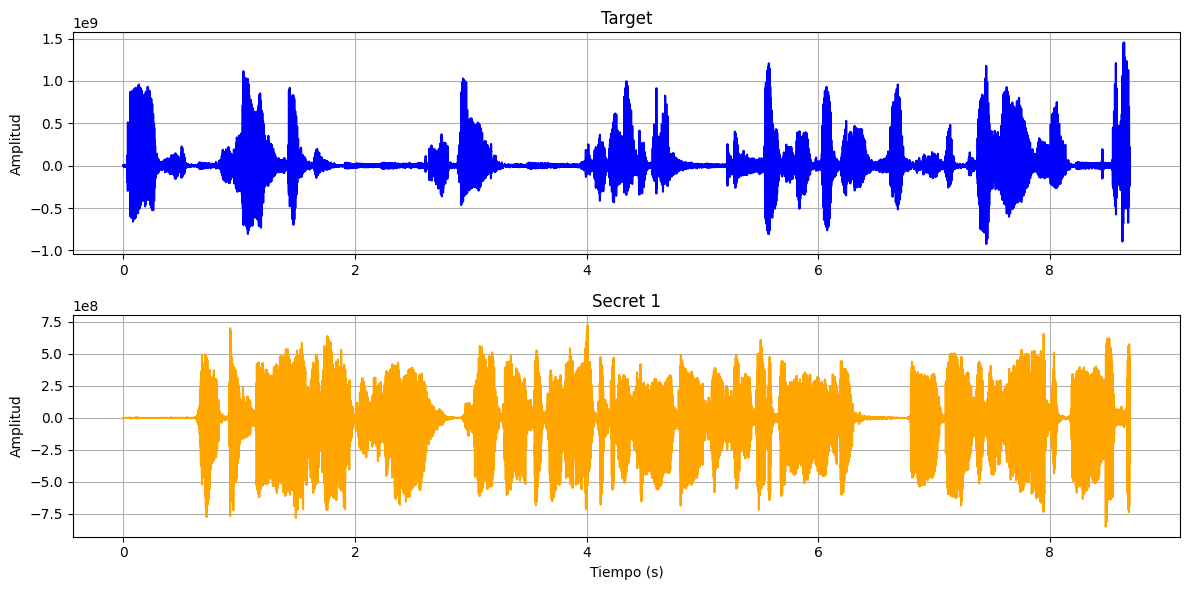

In [53]:

# Convertir las muestras a valores decimales
target = target.astype(float)
secret = secret.astype(float)

# Crear vector de tiempo
tiempo = np.arange(len(target)) / fs_target

# Graficar ambos audios
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(tiempo, target, color="blue")
plt.title("Target")
plt.ylabel("Amplitud")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(tiempo, secret, color="orange")
plt.title("Secret 1")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()

plt.tight_layout()
plt.show()


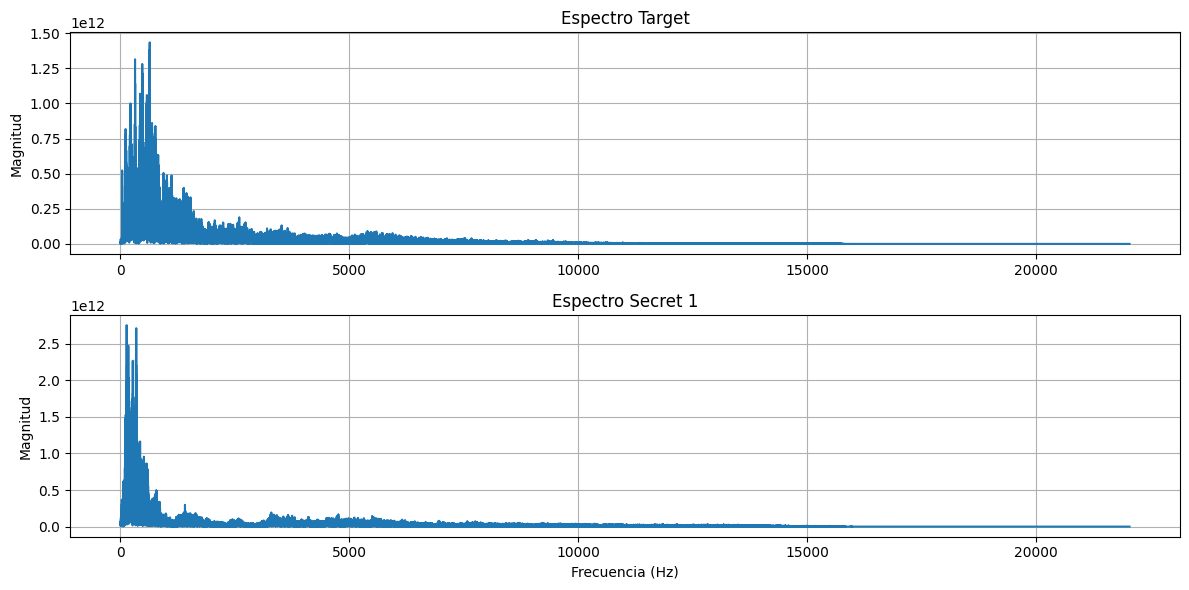

In [54]:

# Transformar las señales a frecuencia
T = rfft(target)
S = rfft(secret)

# Vector de frecuencias
frecuencias = np.fft.rfftfreq(
    len(target), d=1/fs_target
)

# Graficar los espectros
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(frecuencias, np.abs(T))
plt.title("Espectro Target")
plt.ylabel("Magnitud")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(frecuencias, np.abs(S))
plt.title("Espectro Secret 1")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.grid()

plt.tight_layout()
plt.show()


In [55]:

# Normalizar las señales originales
fs_target, target = read("target.wav")
fs_secret, secret = read("secret1.wav")

target = target.astype(np.float64) / 2**31
secret = secret.astype(np.float64) / 2**31

# Calcular nuevamente las transformadas
T = rfft(target)
S = rfft(secret)

# Crear los índices originales
K = np.arange(len(S))

# Posiciones que podemos reorganizar
# Dejamos fijos DC y Nyquist
P = np.arange(1, len(S) - 1)

# Ordenar según las magnitudes
I1 = np.argsort(np.abs(S[P]))
I2 = np.argsort(np.abs(T[P]))

# Construir la clave
K[P[I2]] = P[I1]

# Reorganizar los coeficientes complejos
E = S[K]

print("Clave creada correctamente")
print("Número de coeficientes:", len(K))


Clave creada correctamente
Número de coeficientes: 191593


In [56]:

# Reconstruir la señal codificada
encoded = irfft(E, n=len(secret))

# Guardar el audio oculto
write("encoded.wav", fs_secret,
      encoded.astype(np.float32))

# Guardar la clave
np.savetxt(
    "FFT_key.csv",
    K,
    fmt="%d",
    delimiter=",",
    header="key",
    comments=""
)

# Escuchar el audio
print("Audio codificado:")
display(Audio(encoded, rate=fs_secret))

print("Archivos generados correctamente")


Audio codificado:


Archivos generados correctamente


In [57]:

# Cargar el audio codificado y su clave
fs, encoded_audio = read("encoded.wav")

key = np.loadtxt(
    "FFT_key.csv",
    delimiter=",",
    skiprows=1,
    dtype=int
)

# Transformada de Fourier
X_encoded = rfft(encoded_audio.astype(float))

# Recuperar posiciones originales
X_recovered = np.empty_like(X_encoded)
X_recovered[key] = X_encoded

# Transformada inversa
recovered = irfft(
    X_recovered,
    n=len(encoded_audio)
)

# Guardar el mensaje recuperado
write("recovered.wav", fs,
      recovered.astype(np.float32))

# Escuchar mensaje recuperado
print("Mensaje secreto recuperado:")
display(Audio(recovered, rate=fs))


Mensaje secreto recuperado:


In [58]:

from scipy.io.wavfile import read, write
from scipy.fft import rfft, irfft
import numpy as np

# Cargar audio de referencia
fs_target, target = read("target.wav")
target = target.astype(np.float64) / 2**31

T = rfft(target)

# Procesar los cinco mensajes
for i in range(1, 6):

    fs, secret = read(f"secret{i}.wav")
    secret = secret.astype(np.float64) / 2**31

    assert fs == fs_target
    assert len(secret) == len(target)

    # Transformada de Fourier
    S = rfft(secret)

    # Construir clave de permutación
    K = np.arange(len(S))
    P = np.arange(1, len(S) - 1)

    I1 = np.argsort(np.abs(S[P]))
    I2 = np.argsort(np.abs(T[P]))

    K[P[I2]] = P[I1]

    # Ocultar mensaje
    E = S[K]
    encoded = irfft(E, n=len(secret))

    # Guardar mensaje oculto
    write(f"encoded{i}.wav", fs,
          encoded.astype(np.float32))

    # Guardar clave
    np.savetxt(
        f"FFT_key{i}.csv",
        K,
        fmt="%d",
        delimiter=",",
        header="key",
        comments=""
    )

    # Recuperar mensaje desde archivos guardados
    _, encoded_file = read(f"encoded{i}.wav")
    key = np.loadtxt(
        f"FFT_key{i}.csv",
        delimiter=",",
        skiprows=1,
        dtype=int
    )

    X = rfft(encoded_file.astype(np.float64))
    X_rec = np.empty_like(X)
    X_rec[key] = X

    recovered = irfft(X_rec, n=len(secret))

    # Guardar audio recuperado
    write(f"recovered{i}.wav", fs,
          recovered.astype(np.float32))

    print(f"Secret {i}: proceso completado")

print("¡Los cinco mensajes fueron procesados!")



Secret 1: proceso completado
Secret 2: proceso completado
Secret 3: proceso completado
Secret 4: proceso completado
Secret 5: proceso completado
¡Los cinco mensajes fueron procesados!


In [59]:

from IPython.display import Audio, display

for i in range(1, 6):
    print(f"\n SECRET {i} ")

    print("1. Audio original:")
    display(Audio(filename=f"secret{i}.wav"))

    print("2. Audio oculto (Encoded):")
    display(Audio(filename=f"encoded{i}.wav"))

    print("3. Audio recuperado (Recovered):")
    display(Audio(filename=f"recovered{i}.wav"))


Output hidden; open in https://colab.research.google.com to view.

In [64]:

import numpy as np
import pandas as pd
from scipy.io.wavfile import read
from IPython.display import display, HTML, Math

#
# TÍTULO PRINCIPAL
#

display(HTML("""
<div style="text-align:center;">
    <h2>Evaluación de la calidad de reconstrucción</h2>
    <p>Comparación de los cinco audios originales
    con sus respectivas señales recuperadas.</p>
</div>
<hr>
"""))

#
# 1. RELACIÓN SEÑAL A RUIDO (SNR)
#

display(HTML("""
<div style="text-align:center;">
    <h3>1. Relación señal a ruido (SNR)</h3>
    <p>Mide la calidad de reconstrucción comparando
    la energía de la señal original con la energía
    del error. Cuanto mayor sea el SNR,
    mejor será la recuperación del audio.</p>
</div>
"""))

display(Math(
    r"SNR = 10\log_{10}\left("
    r"\frac{\sum_{n=0}^{N-1}x[n]^2}"
    r"{\sum_{n=0}^{N-1}(x[n]-\hat{x}[n])^2}"
    r"\right)"
))

#
# 2. CORRELACIÓN DE PEARSON
#

display(HTML("""
<div style="text-align:center;">
    <h3>2. Correlación de Pearson</h3>
    <p>Mide la similitud lineal entre la señal
    original y la recuperada. Un valor cercano
    a 1 indica que ambas señales presentan
    formas de onda muy similares.</p>
</div>
"""))

display(Math(
    r"\rho = \frac{\operatorname{Cov}(x,\hat{x})}"
    r"{\sigma_x\sigma_{\hat{x}}}"
))

#
# 3. CÁLCULO DE LAS MÉTRICAS
#

resultados = []

for i in range(1, 6):

    # Cargar audio original
    _, original = read(f"secret{i}.wav")
    original = original.astype(np.float64) / 2**31

    # Cargar audio recuperado
    _, recuperado = read(f"recovered{i}.wav")
    recuperado = recuperado.astype(np.float64)

    # Calcular error
    error = original - recuperado

    # Calcular SNR
    potencia_senal = np.sum(original**2)
    potencia_error = np.sum(error**2)

    if potencia_error == 0:
        snr = np.inf
    else:
        snr = 10 * np.log10(
            potencia_senal / potencia_error
        )

    # Calcular correlación de Pearson
    correlacion = np.corrcoef(
        original, recuperado
    )[0, 1]

    resultados.append([
        f"Secret {i}",
        snr,
        correlacion
    ])

# ==========================================
# 4. TABLA DE RESULTADOS
#

tabla = pd.DataFrame(
    resultados,
    columns=[
        "Mensaje",
        "SNR (dB)",
        "Correlación de Pearson"
    ]
)

display(HTML("""
<hr>
<h3 style="text-align:center;">
Resultados de los cinco mensajes
</h3>
"""))

# Mostrar tabla centrada
tabla_html = tabla.to_html(
    index=False,
    formatters={
        "SNR (dB)": lambda x: f"{x:.2f}",
        "Correlación de Pearson": lambda x: f"{x:.10f}"
    },
    border=1
)

display(HTML(
    '<div style="display:flex;justify-content:center;">'
    + tabla_html
    + '</div>'
))

# Guardar resultados
tabla.to_csv("resultados.csv", index=False)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Mensaje,SNR (dB),Correlación de Pearson
Secret 1,152.42,1.0000000000
Secret 2,152.21,1.0000000000
Secret 3,152.41,1.0000000000
Secret 4,152.37,1.0000000000
Secret 5,152.27,1.0000000000
